In [2]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import numpy as np

In [3]:
def visualizar_desde_corte_subgrafo(Z, ax, n_clusters=3, method="ward"):
    n = Z.shape[0] + 1

    if not isinstance(n_clusters, (int, np.integer)) or not (
        1 < n_clusters < n
    ):
        raise ValueError(f"n_clusters debe ser un entero entre 2 y {n - 1}.")

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=n_clusters,
        show_leaf_counts=True,
        ax=ax,
    )

    # Comprobar si existe un corte horizontal que separe
    # las últimas n_clusters hojas condensadas.
    indice = n - n_clusters
    altura_inferior = np.max(Z[:indice, 2])
    altura_superior = np.min(Z[indice:, 2])

    if altura_inferior < altura_superior:
        corte = (altura_inferior + altura_superior) / 2

        ax.axhline(
            corte,
            color="red",
            linestyle="--",
            label=f"Corte: {corte:.2f}",
        )
        ax.legend()
    else:
        ax.text(
            0.03, 0.95,
            "Sin corte horizontal para esta partición",
            transform=ax.transAxes,
            va="top",
            fontsize=8,
        )

    ax.set_title(f"{method.upper()} — {n_clusters} grupos condensados")
    ax.set_xlabel("Grupos condensados")
    ax.set_ylabel("Distancia de fusión")


def visualizar_desde_corte(resultados: dict, n_clusters=3):
    if not resultados:
        raise ValueError("El diccionario resultados está vacío.")

    n_columnas = 3
    n_filas = int(np.ceil(len(resultados) / n_columnas))

    fig, axes = plt.subplots(
        n_filas,
        n_columnas,
        figsize=(18, 4 * n_filas),
        squeeze=False,
        layout="constrained",
    )

    for ax, (metodo, Z) in zip(axes.flat, resultados.items()):
        visualizar_desde_corte_subgrafo(
            Z,
            ax=ax,
            n_clusters=n_clusters,
            method=metodo,
        )

    for ax in list(axes.flat)[len(resultados):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Comparación de jerarquías truncadas ({n_clusters} grupos)",
        fontsize=16,
    )
    plt.show()

In [4]:
def visualizar_completo_subgrafo(Z, ax, method="ward"):
    
    dendrogram(Z, ax=ax)
    ax.set_title(f"Clustering jerárquico aglomerativo ({method})")
    ax.set_xlabel("Observaciones")
    ax.set_ylabel("Distancia de fusión")
    #plt.tight_layout()
    #plt.show()

def visualizar_completo(resultados: dict):
    n_columnas = 3
    n_filas = int(np.ceil(len(resultados) / n_columnas))

    fig, axes = plt.subplots(n_filas, n_columnas,
                             figsize=(18, 4 * n_filas),
                             squeeze=False,layout="constrained",
    )

    # Dibujar cada método en su subgráfico.
    for ax, (metodo, Z) in zip(axes.flat, resultados.items()):
        visualizar_completo_subgrafo(Z, ax=ax, method=metodo)

    # Ocultar los espacios sobrantes.
    for ax in list(axes.flat)[len(resultados):]:
        ax.set_visible(False)

    fig.suptitle("Comparación de jerarquías completas", fontsize=16)
    plt.show()


In [5]:
def visualizar_clusters_2d_3d_subgrafo(
    X, Z, ax2d, ax3d, n_clusters=3, method="ward"
):
    X = np.asarray(X)

    if X.ndim != 2 or X.shape[1] != 3:
        raise ValueError("X debe tener exactamente tres características.")

    if X.shape[0] != Z.shape[0] + 1:
        raise ValueError("X y Z deben corresponder a las mismas observaciones.")

    if not isinstance(n_clusters, (int, np.integer)) or not (
        1 <= n_clusters <= len(X)
    ):
        raise ValueError("n_clusters debe ser un entero entre 1 y len(X).")

    etiquetas = fcluster(Z, t=n_clusters, criterion="maxclust")
    grupos = np.unique(etiquetas)
    colores = plt.get_cmap("tab10")

    for i, grupo in enumerate(grupos):
        puntos = X[etiquetas == grupo]

        estilo = {
            "color": colores(i % 10),
            "label": f"Clúster {grupo} (n={len(puntos)})",
            "s": 70,
            "edgecolors": "black",
            "alpha": 0.8,
        }

        ax2d.scatter(puntos[:, 0], puntos[:, 1], **estilo)
        ax3d.scatter(
            puntos[:, 0], puntos[:, 1], puntos[:, 2],
            **estilo,
        )

    ax2d.set_title(f"{method.upper()} — 2D ({len(grupos)} grupos)")
    ax2d.set_xlabel("Característica 1")
    ax2d.set_ylabel("Característica 2")
    ax2d.grid(alpha=0.2)
    ax2d.legend(fontsize=8)

    ax3d.set_title(f"{method.upper()} — 3D ({len(grupos)} grupos)")
    ax3d.set_xlabel("Característica 1")
    ax3d.set_ylabel("Característica 2")
    ax3d.set_zlabel("Característica 3")
    ax3d.view_init(elev=25, azim=45)
    ax3d.legend(fontsize=8)

    return etiquetas


def visualizar_clusters_2d_3d(X, resultados: dict, n_clusters=3):
    if not resultados:
        raise ValueError("El diccionario resultados está vacío.")

    n_filas = len(resultados)

    fig = plt.figure(
        figsize=(14, 5 * n_filas),
        layout="constrained",
    )

    # Matriz de subgráficos: una columna 2D y otra 3D.
    layout = fig.add_gridspec(n_filas, 2)
    etiquetas_por_metodo = {}

    for fila, (metodo, Z) in enumerate(resultados.items()):
        ax2d = fig.add_subplot(layout[fila, 0])
        ax3d = fig.add_subplot(layout[fila, 1], projection="3d")

        etiquetas_por_metodo[metodo] = visualizar_clusters_2d_3d_subgrafo(
            X,
            Z,
            ax2d=ax2d,
            ax3d=ax3d,
            n_clusters=n_clusters,
            method=metodo,
        )

    fig.suptitle(
        "Comparación de clústeres en 2D y 3D",
        fontsize=16,
    )
    plt.show()

    return etiquetas_por_metodo

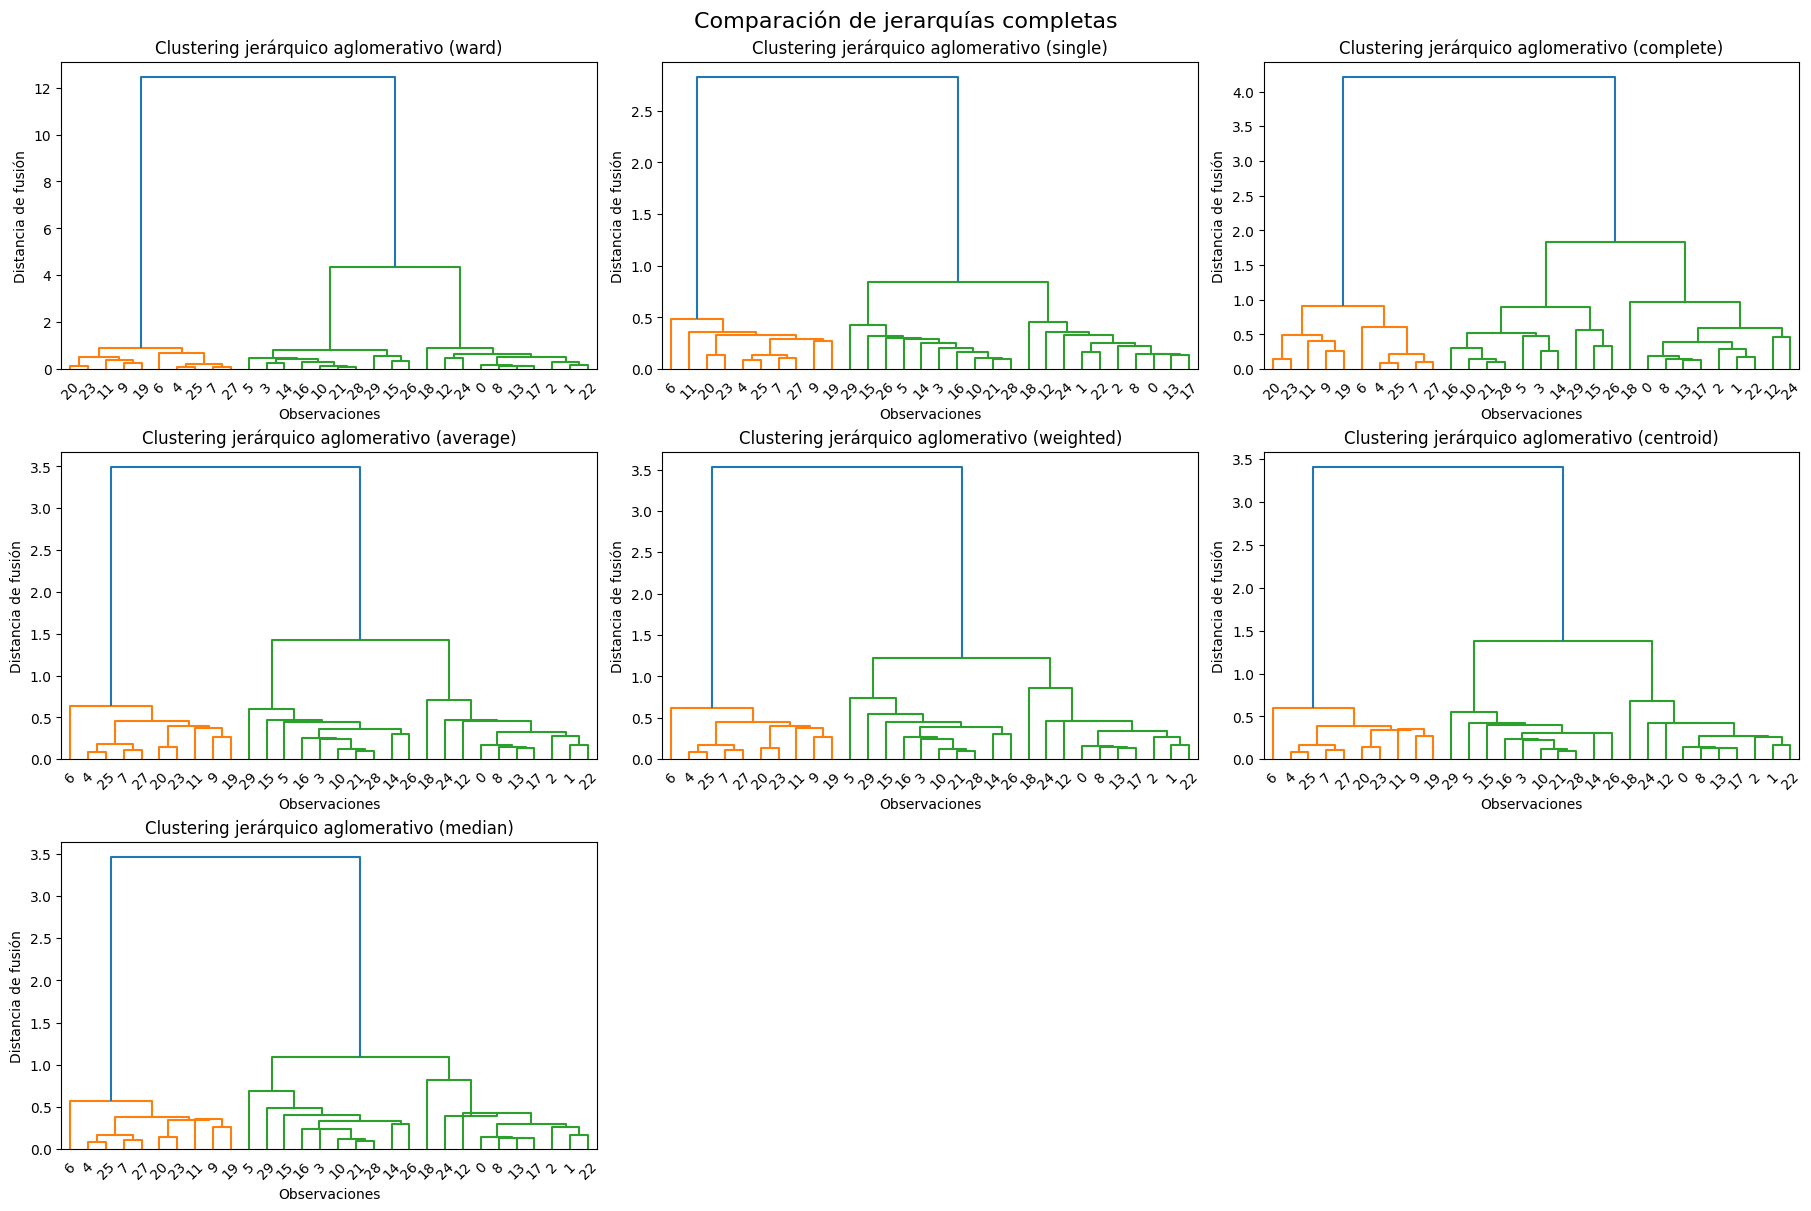

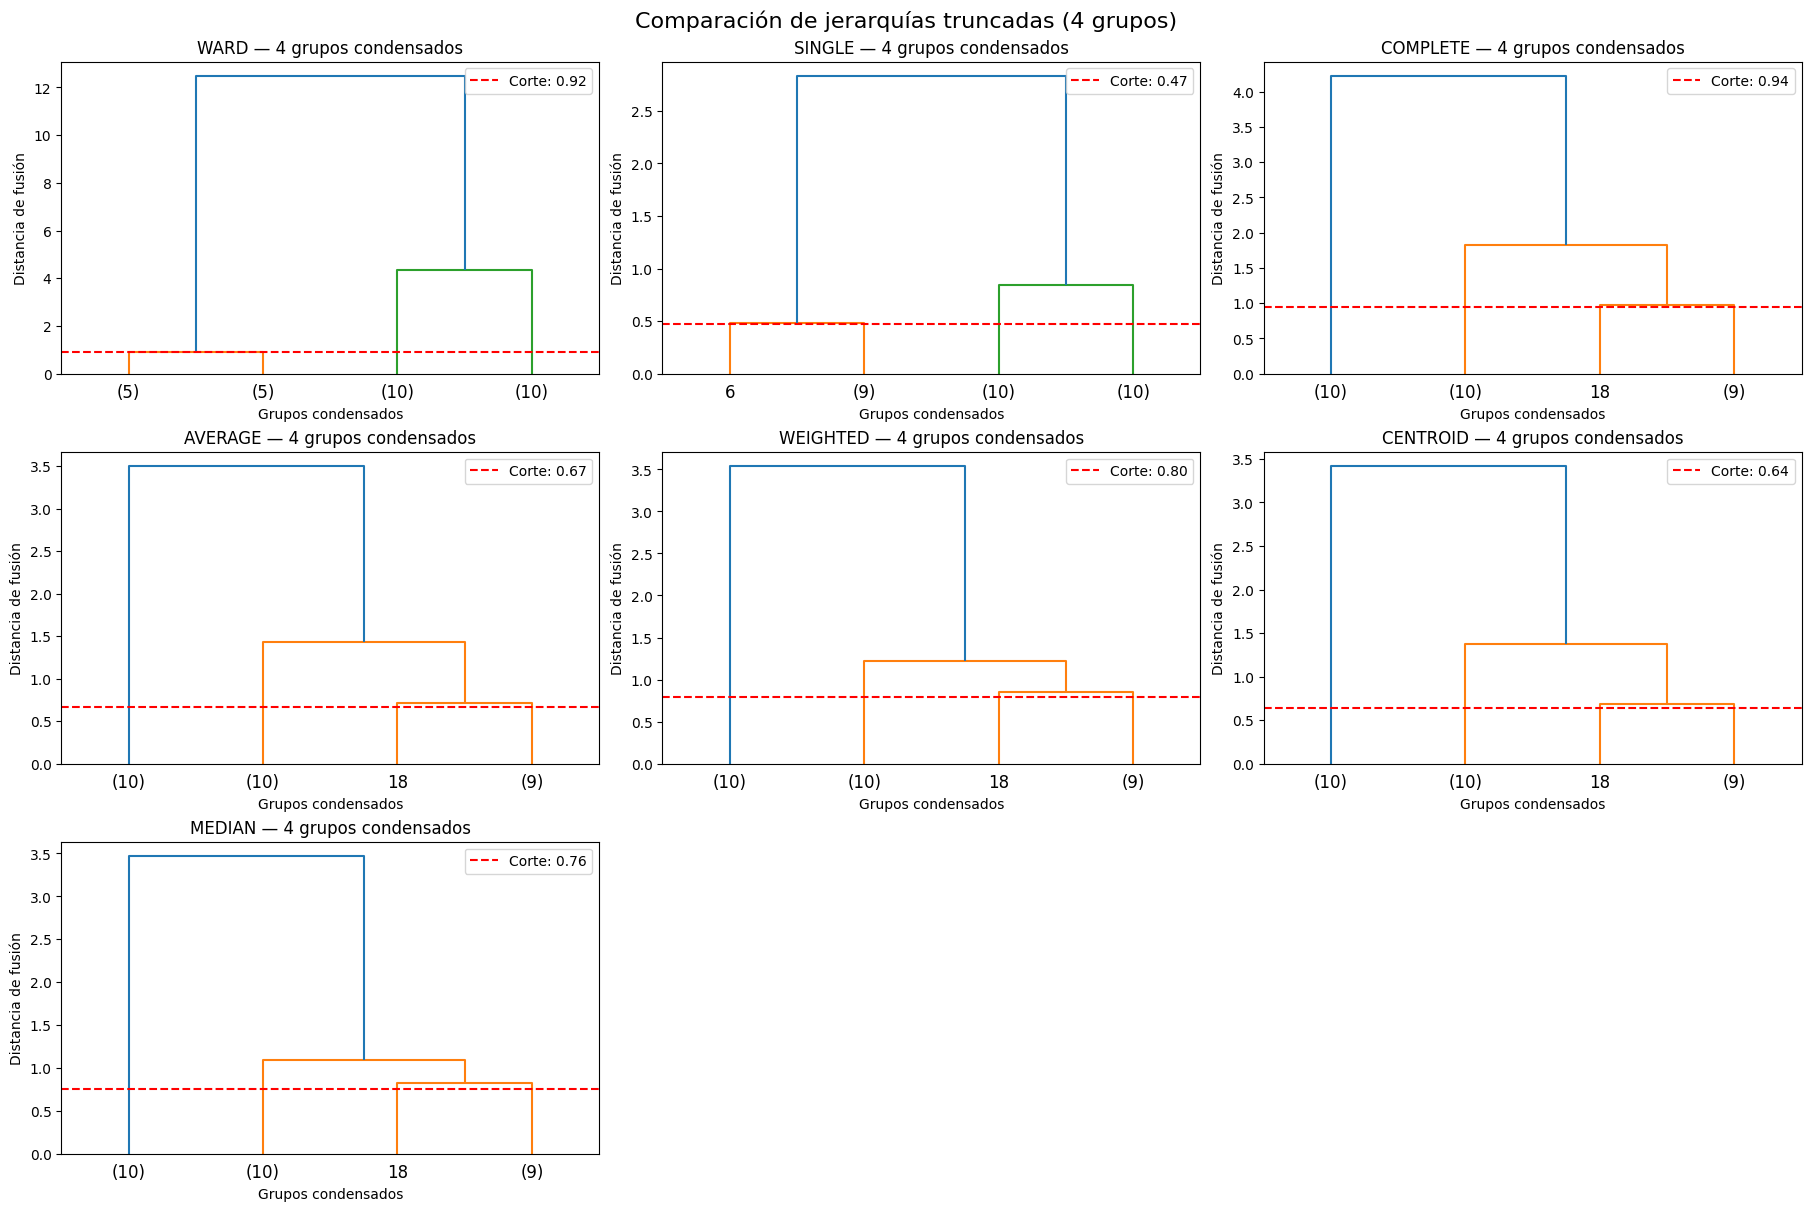

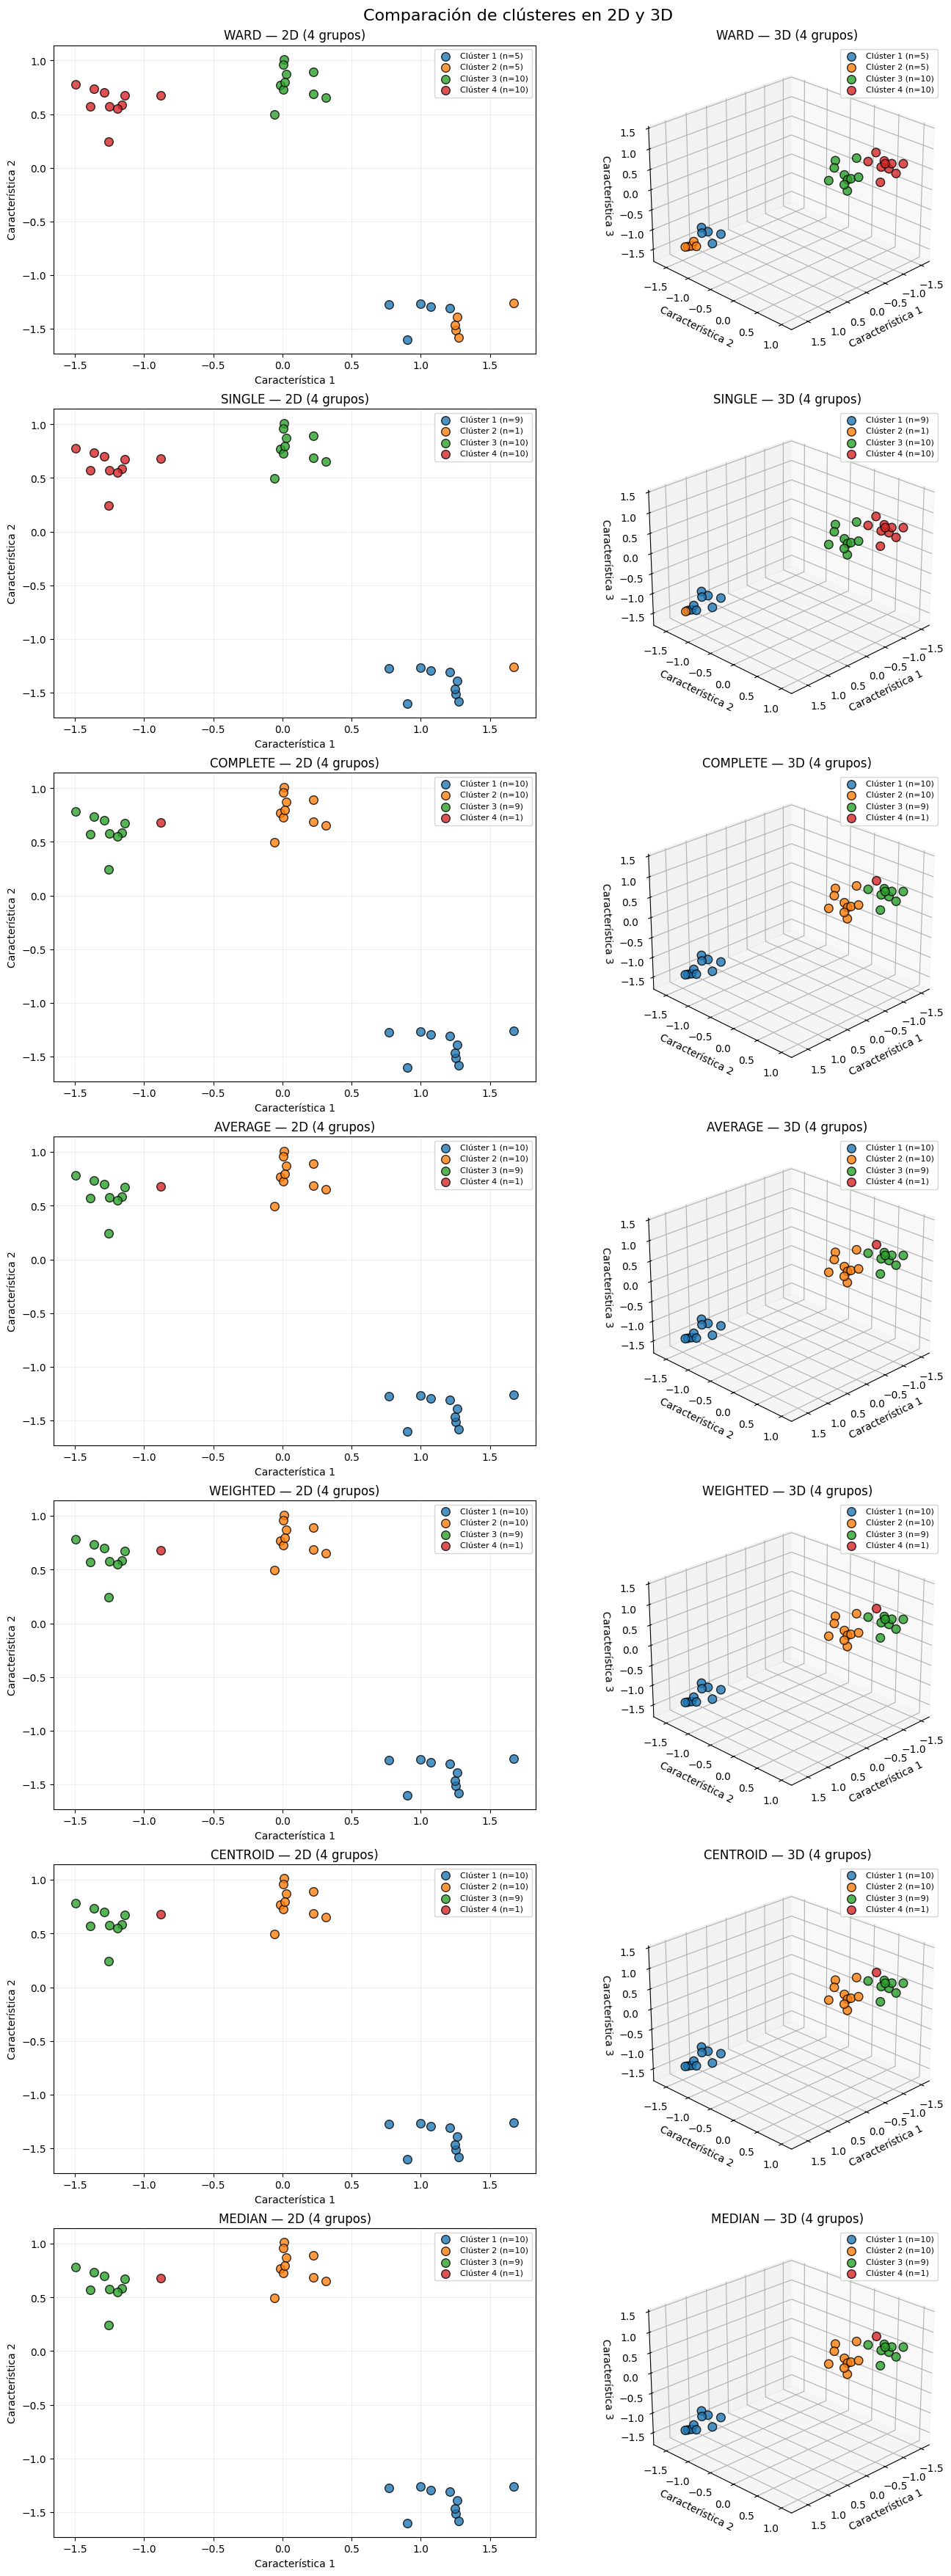

{'ward': array([4, 4, 4, 3, 2, 3, 2, 2, 4, 1, 3, 1, 4, 4, 3, 3, 3, 4, 4, 1, 1, 3,
        4, 1, 4, 2, 3, 2, 3, 3], dtype=int32),
 'single': array([4, 4, 4, 3, 1, 3, 2, 1, 4, 1, 3, 1, 4, 4, 3, 3, 3, 4, 4, 1, 1, 3,
        4, 1, 4, 1, 3, 1, 3, 3], dtype=int32),
 'complete': array([3, 3, 3, 2, 1, 2, 1, 1, 3, 1, 2, 1, 3, 3, 2, 2, 2, 3, 4, 1, 1, 2,
        3, 1, 3, 1, 2, 1, 2, 2], dtype=int32),
 'average': array([3, 3, 3, 2, 1, 2, 1, 1, 3, 1, 2, 1, 3, 3, 2, 2, 2, 3, 4, 1, 1, 2,
        3, 1, 3, 1, 2, 1, 2, 2], dtype=int32),
 'weighted': array([3, 3, 3, 2, 1, 2, 1, 1, 3, 1, 2, 1, 3, 3, 2, 2, 2, 3, 4, 1, 1, 2,
        3, 1, 3, 1, 2, 1, 2, 2], dtype=int32),
 'centroid': array([3, 3, 3, 2, 1, 2, 1, 1, 3, 1, 2, 1, 3, 3, 2, 2, 2, 3, 4, 1, 1, 2,
        3, 1, 3, 1, 2, 1, 2, 2], dtype=int32),
 'median': array([3, 3, 3, 2, 1, 2, 1, 1, 3, 1, 2, 1, 3, 3, 2, 2, 2, 3, 4, 1, 1, 2,
        3, 1, 3, 1, 2, 1, 2, 2], dtype=int32)}

In [6]:
# Datos de ejemplo: 30 observaciones con tres características.
X, _ = make_blobs(
    n_samples=30,
    n_features=3,
    centers=3,
    cluster_std=1.0,
    random_state=42,
)

X_escalado = StandardScaler().fit_transform(X)

metodos = [
    "ward",
    "single",
    "complete",
    "average",
    "weighted",
    "centroid",
    "median",
]

n_clusters = 4

# Calcular una sola vez el linkage de cada método.
resultados = {
    metodo: linkage(X_escalado, method=metodo, metric="euclidean")
    for metodo in metodos
}

visualizar_completo(resultados)
visualizar_desde_corte(resultados, n_clusters=n_clusters)
visualizar_clusters_2d_3d(X_escalado, resultados, n_clusters=n_clusters)

# # 1. Todas las jerarquías completas.
# print("\nJERARQUÍAS COMPLETAS")

# for metodo, Z in resultados.items():
#     vizualizar_completo(Z, method=metodo)

# # 2. Todas las jerarquías truncadas.
# print("\nJERARQUÍAS TRUNCADAS")

# for metodo, Z in resultados.items():
#     visualizar_desde_corte(
#         Z,
#         n_clusters=n_clusters,
#         method=metodo,
#     )

# # 3. Todos los diagramas de dispersión.
# print("\nDIAGRAMAS DE DISPERSIÓN 2D Y 3D")

# for metodo, Z in resultados.items():
#     visualizar_clusters_2d_3d(
#         X_escalado,
#         Z,
#         n_clusters=n_clusters,
#         method=metodo,
#     )